In [16]:
!pip install pandas openpyxl

Explanation
Read the Data File: The script reads the CSV file into a pandas DataFrame.
Initialize Output Columns: New columns for OUT0 to OUT4 are initialized.
Calculate Outputs: The script calculates each output based on the logic provided.
Save Results: The script saves the resulting DataFrame to a new CSV file named output_sequence.csv.
Format and Print Sequence: The script formats each row into the desired x -> y -> z format and prints it.

In [ ]:
import pandas as pd

# Read the data file
data = pd.read_csv('/mnt/data/data.csv')

# Initialize output columns
data['OUT0'] = 0
data['OUT1'] = 0
data['OUT2'] = 0
data['OUT3'] = 0
data['OUT4'] = 0

# Calculate the outputs based on the logic provided
data['OUT0'] = (~data['Q1'] & ~data['Q2']).astype(int)
data['OUT1'] = (data['Q1'] & data['Q2']).astype(int)
data['OUT2'] = (data['Q2'] & ~data['Q3']).astype(int)
data['OUT3'] = (data['Q1'] & data['Q3']).astype(int)
data['OUT4'] = (~data['Q1'] & data['Q3']).astype(int)

# Save the results to a new CSV file
data.to_csv('/mnt/data/output_sequence.csv', index=False)

# Function to format the sequence for printing
def format_sequence(row):
    return f"{row['OUT0']} -> {row['OUT1']} -> {row['OUT2']} -> {row['OUT3']} -> {row['OUT4']}"

# Apply the function to each row to get the sequence in the desired format
sequence = data.apply(format_sequence, axis=1)

# Print the sequence
for step in sequence:
    print(step)

print("Output sequence saved to 'output_sequence.csv'")


I'll guide you through the process of reading an Excel file with multiple sheets, extracting the relevant data, simplifying it to create a binary table (0-1), and then processing this data for further analysis.

Step-by-Step Guide
Read the Excel File: Load the Excel file and read the relevant sheets into pandas DataFrames.
Simplify the Data: Convert the data into a binary table format (0-1).
Save and Display the Simplified Data: Save the simplified data to a new CSV file and display it.
Sample Python Script
Let's assume your Excel file is named output_data.xlsx and it contains sheets named Sheet1 and Sheet2.

In [22]:
import pandas as pd

# Load the Excel file
file_path = 'G:/My Drive/Study/UQS/SCE1202orELE1301 - Computer Engineering/Assesment/A1C.xlsx'
xls = pd.ExcelFile(file_path)

# Display sheet names
print(xls.sheet_names)

# Read relevant sheets
df_z0 = pd.read_excel(xls, sheet_name='Z=0')
df_z1 = pd.read_excel(xls, sheet_name='Z=1')

# Display the first few rows of each sheet to understand the structure
print("First few rows of Z=0:")
print(df_z0.head())

print("First few rows of Z=1:")
print(df_z1.head())

['System overview', 'Z=0', 'Z=1']
First few rows of Z=0:
           Time  CLK  OUT0  OUT1  OUT2  OUT3  OUT4
0  0.000000e+00   12    11     8     6     4     2
1  1.000000e-15   12    11     8     6     4     2
2  1.000000e-08   12    11     8     6     4     2
3  1.000000e-02   12    11     8     6     4     2
4  2.000000e-02   12    11     8     6     4     2
First few rows of Z=1:
           Time  CLK  OUT0  OUT1  OUT2  OUT3  OUT4
0  0.000000e+00   12    11     8     6     4     2
1  1.000000e-15   12    11     8     6     4     2
2  1.000000e-08   12    11     8     6     4     2
3  1.000000e-02   12    11     8     6     4     2
4  2.000000e-02   12    11     8     6     4     2


3. Transform Data to Binary Format
We'll use a threshold value to convert the signal values into binary format. For instance, if the value is above a certain threshold, it becomes 1, otherwise 0.

In [23]:
# Define thresholds for each column
thresholds = {'CLK': 12, 'OUT0': 10, 'OUT1': 8, 'OUT2': 6, 'OUT3': 4, 'OUT4': 2}

# Define a function to threshold the values based on the specific thresholds
def threshold_signal(value, column):
    if column == 'CLK':
        return 1 if value > 12 else 0
    elif column == 'OUT0':
        return 1 if value > 10 else 0
    elif column == 'OUT1':
        return 1 if value > 8 else 0
    elif column == 'OUT2':
        return 1 if value > 6 else 0
    elif column == 'OUT3':
        return 1 if value > 4 else 0
    elif column == 'OUT4':
        return 1 if value > 2 else 0
    else:
        return 0

# Apply thresholding to each relevant column
binary_data_z0 = df_z0.copy()
binary_data_z1 = df_z1.copy()

for column in ['CLK', 'OUT0', 'OUT1', 'OUT2', 'OUT3', 'OUT4']:
    binary_data_z0[column] = binary_data_z0[column].apply(lambda x: threshold_signal(x, column))
    binary_data_z1[column] = binary_data_z1[column].apply(lambda x: threshold_signal(x, column))

# Add the Z column back to the DataFrame
binary_data_z0['Z'] = 0
binary_data_z1['Z'] = 1

# Reorder columns to match the desired output format
binary_data_z0 = binary_data_z0[['Z', 'CLK', 'OUT0', 'OUT1', 'OUT2', 'OUT3', 'OUT4']]
binary_data_z1 = binary_data_z1[['Z', 'CLK', 'OUT0', 'OUT1', 'OUT2', 'OUT3', 'OUT4']]

# Display the simplified binary data
print("Binary data for Z=0:")
print(binary_data_z0.head())

print("Binary data for Z=1:")
print(binary_data_z1.head())


Binary data for Z=0:
   Z  CLK  OUT0  OUT1  OUT2  OUT3  OUT4
0  0    0     1     0     0     0     0
1  0    0     1     0     0     0     0
2  0    0     1     0     0     0     0
3  0    0     1     0     0     0     0
4  0    0     1     0     0     0     0
Binary data for Z=1:
   Z  CLK  OUT0  OUT1  OUT2  OUT3  OUT4
0  1    0     1     0     0     0     0
1  1    0     1     0     0     0     0
2  1    0     1     0     0     0     0
3  1    0     1     0     0     0     0
4  1    0     1     0     0     0     0


 Remove Consecutive Duplicate Rows

In [25]:
# Function to remove consecutive duplicate rows
def remove_consecutive_duplicates(df):
    return df.loc[(df.shift() != df).any(axis=1)]

# Apply the function to remove consecutive duplicates
binary_data_z0_unique = remove_consecutive_duplicates(binary_data_z0)
binary_data_z1_unique = remove_consecutive_duplicates(binary_data_z1)

# Display the data without consecutive duplicates
print("Binary data for Z=0 without consecutive duplicates:")
print(binary_data_z0_unique.head())

print("Binary data for Z=1 without consecutive duplicates:")
print(binary_data_z1_unique.head())


Binary data for Z=0 without consecutive duplicates:
     Z  CLK  OUT0  OUT1  OUT2  OUT3  OUT4
0    0    0     1     0     0     0     0
54   0    1     1     0     0     0     0
56   0    1     1     1     0     0     0
57   0    1     0     1     0     0     0
109  0    0     0     1     0     0     0
Binary data for Z=1 without consecutive duplicates:
     Z  CLK  OUT0  OUT1  OUT2  OUT3  OUT4
0    1    0     1     0     0     0     0
54   1    1     1     0     0     0     0
56   1    1     1     1     0     0     0
57   1    1     0     1     0     0     0
109  1    0     0     1     0     0     0


In [28]:
# Save the simplified data to new CSV files
binary_data_z0_unique.to_csv('G:/My Drive/Study/UQS/SCE1202orELE1301 - Computer Engineering/Assesment/A1C_1.csv', index=False)
binary_data_z1_unique.to_csv('G:/My Drive/Study/UQS/SCE1202orELE1301 - Computer Engineering/Assesment/A1C_2.csv', index=False)


# Display a message indicating where the files have been saved
print("Output sequence tables saved to 'output_sequence_z0.csv' and 'output_sequence_z1.csv'")

Output sequence tables saved to 'output_sequence_z0.csv' and 'output_sequence_z1.csv'


Canonical Sum-of-Products (SOP) form from a truth table using Python. To do this, you'll need to identify the rows in the truth table where the output is 1 and then generate the corresponding minterms for these rows.

Here's a step-by-step guide on how to achieve this:

Step-by-Step Guide
Create the Truth Table: Define your truth table in a suitable format.
Identify Rows with Output 1: Find the rows where the output is 1.
Generate Minterms: Convert these rows into minterms.
Construct the Canonical SOP Form: Combine the minterms using OR operations.

In [30]:
import pandas as pd

# Load the truth table from the CSV file
file_path = 'G:/My Drive/Study/UQS/SCE1202orELE1301 - Computer Engineering/Assesment/A1C_1.csv'  # Update this to the correct file path
truth_table = pd.read_csv(file_path)

# Display the first few rows of the truth table to understand the structure
print("Truth Table:")
print(truth_table)

Truth Table:
    Z  CLK  OUT0  OUT1  OUT2  OUT3  OUT4
0   0    0     1     0     0     0     0
1   0    1     1     0     0     0     0
2   0    1     1     1     0     0     0
3   0    1     0     1     0     0     0
4   0    0     0     1     0     0     0
5   0    1     0     1     0     0     0
6   0    1     0     1     1     0     0
7   0    1     0     0     1     0     0
8   0    0     0     0     1     0     0
9   0    1     0     0     1     0     0
10  0    1     0     0     1     1     0
11  0    1     0     0     0     1     0
12  0    0     0     0     0     1     0
13  0    1     0     0     0     1     0
14  0    1     0     0     0     0     0
15  0    1     0     0     0     0     1
16  0    0     0     0     0     0     1
17  0    1     0     0     0     0     1
18  0    1     0     0     0     0     0
19  0    1     1     0     0     0     0
20  0    0     1     0     0     0     0
21  0    1     1     0     0     0     0
22  0    1     1     1     0     0     0
23 

In [31]:
def generate_minterm(row, input_columns):
    minterm = []
    for col in input_columns:
        if row[col] == 1:
            minterm.append(col)
        else:
            minterm.append(f'~{col}')
    return ' & '.join(minterm)

# Define the input and output columns
input_columns = ['Z', 'CLK', 'OUT0', 'OUT1', 'OUT2', 'OUT3', 'OUT4']

# Generate SOP expressions for each output column
sop_expressions = {}
for output_col in input_columns:
    true_rows = truth_table[truth_table[output_col] == 1]
    minterms = true_rows.apply(generate_minterm, axis=1, input_columns=input_columns)
    canonical_sop = ' | '.join(minterms)
    sop_expressions[output_col] = canonical_sop

# Display SOP expressions
for output_col, sop in sop_expressions.items():
    print(f"Canonical SOP Form for {output_col}: {sop}")


Canonical SOP Form for Z: 
Canonical SOP Form for CLK: ~Z & CLK & OUT0 & ~OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & OUT0 & OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & OUT1 & OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & OUT2 & OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & ~OUT2 & OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & ~OUT2 & OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & ~OUT2 & ~OUT3 & OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & ~OUT2 & ~OUT3 & OUT4 | ~Z & CLK & ~OUT0 & ~OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & OUT0 & ~OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & OUT0 & ~OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & OUT0 & OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & OUT1 & ~OUT2 & ~OUT3 & ~OUT4 | ~Z & CLK & ~OUT0 & OUT1 & ~OUT2 & ~OUT3 & ~OUT4

C:\Users\ilo_l\AppData\Local\Temp\ipykernel_11532\398126048.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + ['00', '01', '11', '10'])
C:\Users\ilo_l\AppData\Local\Temp\ipykernel_11532\398126048.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + ['00', '01', '11', '10'])


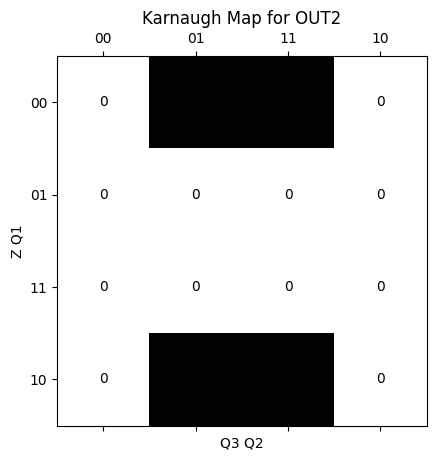

C:\Users\ilo_l\AppData\Local\Temp\ipykernel_11532\398126048.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([''] + ['00', '01', '11', '10'])
C:\Users\ilo_l\AppData\Local\Temp\ipykernel_11532\398126048.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels([''] + ['00', '01', '11', '10'])


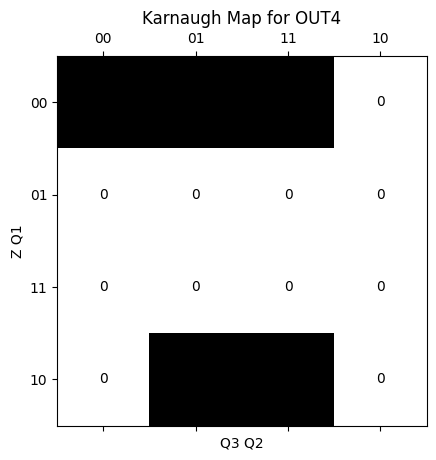

In [32]:
import matplotlib.pyplot as plt
import numpy as np

def plot_kmap(values, title):
    fig, ax = plt.subplots()
    cax = ax.matshow(values, cmap='Greys')
    for (i, j), val in np.ndenumerate(values):
        ax.text(j, i, f'{val}', ha='center', va='center', color='black')
    ax.set_xticklabels([''] + ['00', '01', '11', '10'])
    ax.set_yticklabels([''] + ['00', '01', '11', '10'])
    ax.set_xlabel('Q3 Q2')
    ax.set_ylabel('Z Q1')
    plt.title(title)
    plt.show()

# K-map values for OUT2
kmap_out2 = np.array([
    [0, 1, 1, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 1, 1, 0]
])

# K-map values for OUT4
kmap_out4 = np.array([
    [1, 1, 1, 0],
    [0, 0, 0, 0],
    [0, 0, 0, 0],
    [0, 1, 1, 0]
])

plot_kmap(kmap_out2, "Karnaugh Map for OUT2")
plot_kmap(kmap_out4, "Karnaugh Map for OUT4")
